<a href="https://colab.research.google.com/github/JuliPerezE/SRA-TP-Filtros-Grupo5/blob/main/notebooks/02_Seleccion_de_Componentes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 📊 RECÁLCULO CON VALORES COMERCIALES E24 / E96
• Etapa 1 (RC Pasivo):
  - w_p1 ideal = 5916.25 rad/s (941.60 Hz)
  - w_p1 real  = 5917.16 rad/s (941.75 Hz) | Error: +0.02%
• Etapa 2 (Sallen-Key):
  - w0 ideal   = 6475.10 rad/s (1030.54 Hz)
  - w0 real    = 6463.60 rad/s (1028.71 Hz) | Error: -0.18%
  - Q ideal    = 0.6910
  - Q real     = 0.6786 | Error: -1.81%

📋 TABLA DE MATERIALES REALES (SELECCIÓN ACTIVIDAD 2):


,etapa,referencia,valor_ideal,valor_comercial,tolerancia,justificacion
0,Etapa 1 (RC Pasivo),C0,10.00 nF,10 nF,±5%,Capacitor cerámico/poliéster de valor base com...
1,Etapa 1 (RC Pasivo),R0,16.90 kΩ,16.9 kΩ,±1% (E96),Fija la frecuencia del polo pasivo wp1 = 5917....
2,Etapa 1 (Buffer),AO1,K1 = 1.00,TL082CP,-,Seguidor de tensión. Aísla la celda pasiva del...
3,Etapa 1 (Buffer),R_fb1,0 Ω,0 Ω (Puente),-,Realimentación directa a la entrada inversora ...
4,Etapa 2 (Sallen-Key),C1,19.10 nF,22 nF,±5%,Capacitor de realimentación principal para log...
5,Etapa 2 (Sallen-Key),C2,10.00 nF,10 nF,±5%,Capacitor a masa de referencia para la celda S...
6,Etapa 2 (Sallen-Key),R1,11.17 kΩ,6.8 kΩ,±5% (E24),Resistencia de entrada de la celda activa Sall...
7,Etapa 2 (Sallen-Key),R2,11.17 kΩ,16 kΩ,±5% (E24),Resistencia serie interna de la celda activa S...
8,Etapa 2 (Sallen-Key),AO2,K2 = 1.00,TL082CP,-,OpAmp de la celda Sallen-Key en configuración ...
9,Etapa 2 (Sallen-Key),R_fb2,0 Ω,0 Ω (Puente),-,Realimentación directa a la entrada inversora ...


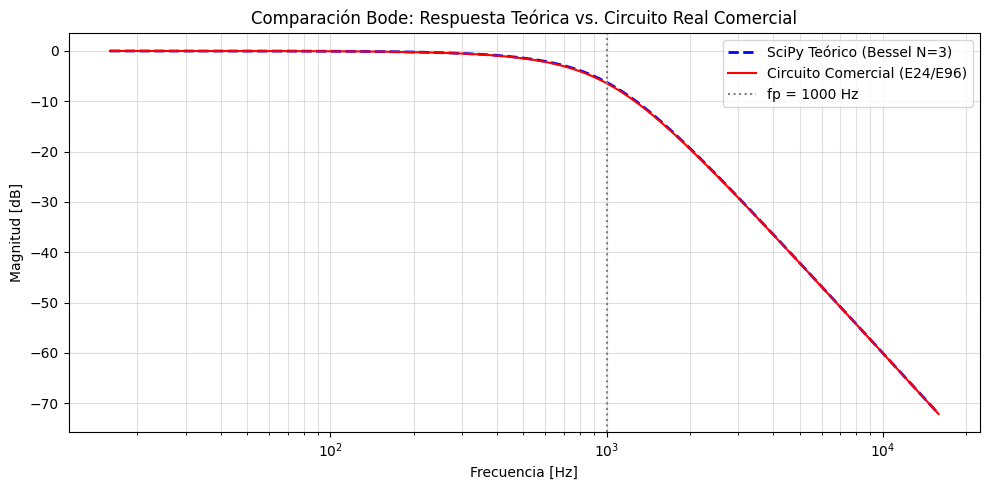

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display

# ==============================================================================
# 1. PARÁMETROS OBJETIVO TEÓRICOS (SciPy - Bessel N=3, fp = 1000 Hz)
# ==============================================================================
fp = 1000.0
wp_val = 2 * np.pi * fp

# Síntesis ideal SciPy
z, p, k = signal.bessel(N=3, Wn=wp_val, btype='lowpass', analog=True, output='zpk', norm='phase')

p_real = [p_i for p_i in p if np.abs(np.imag(p_i)) < 1e-5][0]
p_comp = [p_i for p_i in p if np.abs(np.imag(p_i)) >= 1e-5]

wp1_target = np.abs(p_real)              # 5916.25 rad/s
alpha = np.real(p_comp[0])
beta = np.abs(np.imag(p_comp[0]))
w0_target = np.sqrt(alpha**2 + beta**2)   # 6475.10 rad/s
Q_target = w0_target / (-2 * alpha)       # 0.6910

# ==============================================================================
# 2. SELECCIÓN DE COMPONENTES COMERCIALES (Series E24 y E96)
# ==============================================================================
# Etapa 1 (1.er orden pasivo RC + Buffer)
C0_com = 10e-9       # 10 nF (±5%, poliéster/cerámico)
R0_com = 16900.0     # 16.9 kΩ (±1%, Serie E96)

# Etapa 2 (Sallen-Key Pasabajos)
C1_com = 22e-9       # 22 nF (±5%, poliéster/cerámico)
C2_com = 10e-9       # 10 nF (±5%, poliéster/cerámico)
R1_com = 6800.0      # 6.8 kΩ (±5%, Serie E24)
R2_com = 16000.0     # 16 kΩ (±5%, Serie E24)
K_com  = 1.0         # Buffer seguidor (K = 1)

# ==============================================================================
# 3. RECÁLCULO DE PARÁMETROS REALES (w_p1, w0, Q)
# ==============================================================================
wp1_real = 1 / (R0_com * C0_com)
w0_real  = 1 / np.sqrt(R1_com * R2_com * C1_com * C2_com)
Q_real   = np.sqrt(C1_com * R1_com * R2_com) / (np.sqrt(C2_com) * (R1_com + R2_com))

fp1_real = wp1_real / (2 * np.pi)
f0_real  = w0_real / (2 * np.pi)

err_wp1 = (wp1_real - wp1_target) / wp1_target * 100
err_w0  = (w0_real - w0_target) / w0_target * 100
err_Q   = (Q_real - Q_target) / Q_target * 100

print("=" * 75)
print(" 📊 RECÁLCULO CON VALORES COMERCIALES E24 / E96")
print("=" * 75)
print(f"• Etapa 1 (RC Pasivo):")
print(f"  - w_p1 ideal = {wp1_target:.2f} rad/s ({wp1_target/(2*np.pi):.2f} Hz)")
print(f"  - w_p1 real  = {wp1_real:.2f} rad/s ({fp1_real:.2f} Hz) | Error: {err_wp1:+.2f}%")
print(f"• Etapa 2 (Sallen-Key):")
print(f"  - w0 ideal   = {w0_target:.2f} rad/s ({w0_target/(2*np.pi):.2f} Hz)")
print(f"  - w0 real    = {w0_real:.2f} rad/s ({f0_real:.2f} Hz) | Error: {err_w0:+.2f}%")
print(f"  - Q ideal    = {Q_target:.4f}")
print(f"  - Q real     = {Q_real:.4f} | Error: {err_Q:+.2f}%\n")

# ==============================================================================
# 4. TABLA DE MATERIALES REALES (DATAFRAME)
# ==============================================================================
componentes = pd.DataFrame([
    {
        'etapa': 'Etapa 1 (RC Pasivo)',
        'referencia': 'C0',
        'valor_ideal': '10.00 nF',
        'valor_comercial': '10 nF',
        'tolerancia': '±5%',
        'justificacion': 'Capacitor cerámico/poliéster de valor base comercial.'
    },
    {
        'etapa': 'Etapa 1 (RC Pasivo)',
        'referencia': 'R0',
        'valor_ideal': f"{1/(wp1_target*10e-9)/1000:.2f} kΩ",
        'valor_comercial': '16.9 kΩ',
        'tolerancia': '±1% (E96)',
        'justificacion': 'Fija la frecuencia del polo pasivo wp1 = 5917.16 rad/s (Error: +0.02%).'
    },
    {
        'etapa': 'Etapa 1 (Buffer)',
        'referencia': 'AO1',
        'valor_ideal': 'K1 = 1.00',
        'valor_comercial': 'TL082CP',
        'tolerancia': '-',
        'justificacion': 'Seguidor de tensión. Aísla la celda pasiva del efecto de carga.'
    },
    {
        'etapa': 'Etapa 1 (Buffer)',
        'referencia': 'R_fb1',
        'valor_ideal': '0 Ω',
        'valor_comercial': '0 Ω (Puente)',
        'tolerancia': '-',
        'justificacion': 'Realimentación directa a la entrada inversora para K1 = 1.'
    },
    {
        'etapa': 'Etapa 2 (Sallen-Key)',
        'referencia': 'C1',
        'valor_ideal': f"{10*4*(Q_target**2):.2f} nF",
        'valor_comercial': '22 nF',
        'tolerancia': '±5%',
        'justificacion': 'Capacitor de realimentación principal para lograr Q ≈ 0.6786.'
    },
    {
        'etapa': 'Etapa 2 (Sallen-Key)',
        'referencia': 'C2',
        'valor_ideal': '10.00 nF',
        'valor_comercial': '10 nF',
        'tolerancia': '±5%',
        'justificacion': 'Capacitor a masa de referencia para la celda Sallen-Key.'
    },
    {
        'etapa': 'Etapa 2 (Sallen-Key)',
        'referencia': 'R1',
        'valor_ideal': '11.17 kΩ',
        'valor_comercial': '6.8 kΩ',
        'tolerancia': '±5% (E24)',
        'justificacion': 'Resistencia de entrada de la celda activa Sallen-Key.'
    },
    {
        'etapa': 'Etapa 2 (Sallen-Key)',
        'referencia': 'R2',
        'valor_ideal': '11.17 kΩ',
        'valor_comercial': '16 kΩ',
        'tolerancia': '±5% (E24)',
        'justificacion': 'Resistencia serie interna de la celda activa Sallen-Key.'
    },
    {
        'etapa': 'Etapa 2 (Sallen-Key)',
        'referencia': 'AO2',
        'valor_ideal': 'K2 = 1.00',
        'valor_comercial': 'TL082CP',
        'tolerancia': '-',
        'justificacion': 'OpAmp de la celda Sallen-Key en configuración buffer (K2 = 1).'
    },
    {
        'etapa': 'Etapa 2 (Sallen-Key)',
        'referencia': 'R_fb2',
        'valor_ideal': '0 Ω',
        'valor_comercial': '0 Ω (Puente)',
        'tolerancia': '-',
        'justificacion': 'Realimentación directa a la entrada inversora para K2 = 1.'
    },
    {
        'etapa': 'Alimentación',
        'referencia': 'VCC / VEE',
        'valor_ideal': '±15.0 V',
        'valor_comercial': '±15 V',
        'tolerancia': '±5%',
        'justificacion': 'Tensión de alimentación simétrica estándar para operación lineal del TL082.'
    }
])

print("📋 TABLA DE MATERIALES REALES (SELECCIÓN ACTIVIDAD 2):")
display(componentes)

# ==============================================================================
# 5. VALIDACIÓN BODE: MODELO TEÓRICO vs. COMERCIAL
# ==============================================================================
sys_teorico = signal.TransferFunction(*signal.zpk2tf(z, p, k))

num1 = [1/(R0_com * C0_com)]
den1 = [1, 1/(R0_com * C0_com)]

num2 = [1/(R1_com * R2_com * C1_com * C2_com)]
den2 = [1, (1/(R1_com * C1_com) + 1/(R2_com * C1_com)), 1/(R1_com * R2_com * C1_com * C2_com)]

num_com = np.polymul(num1, num2)
den_com = np.polymul(den1, den2)
sys_comercial = signal.TransferFunction(num_com, den_com)

w_freq = np.logspace(2, 5, 1000)
_, mag_t, phase_t = signal.bode(sys_teorico, w_freq)
_, mag_c, phase_c = signal.bode(sys_comercial, w_freq)

plt.figure(figsize=(10, 5))
plt.semilogx(w_freq / (2 * np.pi), mag_t, 'b--', label='SciPy Teórico (Bessel N=3)', linewidth=2)
plt.semilogx(w_freq / (2 * np.pi), mag_c, 'r-', label='Circuito Comercial (E24/E96)', linewidth=1.5)
plt.axvline(1000, color='gray', linestyle=':', label='fp = 1000 Hz')
plt.title('Comparación Bode: Respuesta Teórica vs. Circuito Real Comercial')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Magnitud [dB]')
plt.grid(True, which='both', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()